> Runs on its own: all the code is inside this notebook (copied from `src/`), so you can open just this file, e.g. in Colab, or run it from the cloned repo (Anaconda Jupyter on Windows/Linux/macOS, or Colab after cloning https://github.com/Rishabh-bgp/geoai-hybrid-ga-pso-anfis-wind-forecasting). Install dependencies once with `%pip install -r requirements.txt` (or `%pip install -r ../requirements.txt` from `notebooks/`). The data cell finds the committed synthetic CSV, downloads it from GitHub, or regenerates it.

# Walkthrough: GA → PSO → ANFIS / CNN-LSTM quantile forecasting
Simplified, CPU-fast version of `src/train_eval.py` (tiny GA/PSO budgets). Reference implementation of my paper, rebuilt on synthetic data; numbers will differ from the published ones.

## Please read first: what these numbers mean
This notebook is a **short teaching demo on synthetic (computer-generated) data**. It is **not** a reproduction of the paper's results, and the numbers below should not be compared with the paper's tables.

- The data in `data/` is made up by a seeded generator. The real SCADA data is confidential and is not in this repository.
- The model trains for only a few minutes on a CPU, so it is much smaller and less tuned than in the paper.
- The model predicts the **change from the last reading** (the *persistence* forecast, "next hour = this hour") and adds it back. A fair test of any wind forecaster is whether it beats persistence, so both are printed side by side, with the real numbers, whatever they are.

In [1]:
# install anything missing (Colab already has most of these)
import importlib.util, subprocess, sys
missing = [m for m in ['numpy','pandas','torch','matplotlib'] if importlib.util.find_spec(m) is None]
if missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + [{'sklearn': 'scikit-learn'}.get(m, m) for m in missing])
import os, urllib.request
from pathlib import Path
os.environ.setdefault('OMP_NUM_THREADS', '2')
REPO = 'geoai-hybrid-ga-pso-anfis-wind-forecasting'

def find_csv(name):
    """../data/synthetic -> data/synthetic -> GitHub raw URL -> regenerate with the seeded generator."""
    for p in [Path.cwd().parent / 'data' / 'synthetic' / name, Path.cwd() / 'data' / 'synthetic' / name]:
        if p.exists(): return p
    out = Path.cwd() / 'data' / 'synthetic' / name; out.parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/Rishabh-bgp/{REPO}/main/data/synthetic/{name}', out); return out
    except Exception as e:
        print('download failed, regenerating synthetic data:', e)
    if name == 'synthetic_sites.csv':
        synthetic_sites(n_hours=24 * 60, seed=0).to_csv(out, index=False)
    else:
        d = synthetic_scada(24 * 120, seed=0); d.index.name = 'timestamp'; d.to_csv(out)
    return out

import numpy as np, torch, matplotlib.pyplot as plt
torch.manual_seed(0); torch.set_num_threads(2)
EPOCHS = 4   # short CPU demo (the full script in src/ trains longer)
print('ready')

ready


## 0. The method's code
This cell holds the model, data and metric code, copied from `src/` so the notebook needs nothing else. You can skip reading it; the steps below use it.

In [2]:
# ===== from src/data.py =====
import numpy as np
import pandas as pd

ALIASES = {
    "wind_speed": ["wind_speed", "windspeed", "wind speed (m/s)", "ws", "wind_speed_ms"],
    "wind_direction": ["wind_direction", "wind direction (°)", "wd", "winddirection"],
    "temperature": ["temperature", "temp", "ambient_temperature"],
    "pressure": ["pressure", "pres"],
    "humidity": ["humidity", "rh"],
    "power": ["power", "lv activepower (kw)", "active_power", "power_kw"],
}

def load_scada_csv(path, freq="1h"):
    df = pd.read_csv(path)
    cols = {c.lower().strip(): c for c in df.columns}
    out = pd.DataFrame()
    tcol = next((cols[c] for c in cols if c in ("timestamp", "date/time", "datetime", "time", "date")), None)
    if tcol is None:
        raise ValueError("CSV needs a timestamp column")
    out["timestamp"] = pd.to_datetime(df[tcol], dayfirst=True, errors="coerce")
    for std, names in ALIASES.items():
        for n in names:
            if n in cols:
                out[std] = pd.to_numeric(df[cols[n]], errors="coerce")
                break
    if "wind_speed" not in out:
        raise ValueError("CSV needs a wind_speed column")
    out = out.dropna(subset=["timestamp"]).set_index("timestamp").sort_index()
    out = out.resample(freq).mean().interpolate(limit=6).dropna()
    return out

def synthetic_scada(n_hours=24 * 120, seed=0):
    """Synthetic hourly SCADA-like series: diurnal + seasonal cycle, AR(1) turbulence,
    occasional gust regimes, Weibull-like marginal. Purely for smoke tests."""
    rng = np.random.default_rng(seed)
    t = np.arange(n_hours)
    base = 7 + 1.5 * np.sin(2 * np.pi * t / 24 - 1.0) + 2.0 * np.sin(2 * np.pi * t / (24 * 365))
    ar = np.zeros(n_hours)
    regime = (np.sin(2 * np.pi * t / 240) + rng.normal(0, .3, n_hours)) > 0.8  # gusty spells
    for i in range(1, n_hours):
        ar[i] = 0.85 * ar[i - 1] + rng.normal(0, 0.6 + 0.9 * regime[i])
    ws = np.clip(base + ar, 0.2, None)
    wd = (200 + 40 * np.sin(2 * np.pi * t / 500) + rng.normal(0, 15, n_hours)) % 360
    temp = 28 + 4 * np.sin(2 * np.pi * t / 24 - 2) + rng.normal(0, .5, n_hours)
    pres = 1008 - 0.6 * ar + rng.normal(0, .4, n_hours)
    hum = np.clip(70 - 8 * np.sin(2 * np.pi * t / 24 - 2) + rng.normal(0, 3, n_hours), 10, 100)
    power = np.clip(3600 / (1 + np.exp(-(ws - 9) * 0.9)) * (ws > 3) * (ws < 25), 0, 3600)
    idx = pd.date_range("2018-01-01", periods=n_hours, freq="h")
    return pd.DataFrame(dict(wind_speed=ws, wind_direction=wd, temperature=temp, pressure=pres,
                             humidity=hum, power=power), index=idx)

def add_features(df):
    d = df.copy()
    h, doy = d.index.hour, d.index.dayofyear
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    d["doy_sin"], d["doy_cos"] = np.sin(2 * np.pi * doy / 365), np.cos(2 * np.pi * doy / 365)
    if "wind_direction" in d:
        r = np.deg2rad(d.pop("wind_direction"))
        d["wd_sin"], d["wd_cos"] = np.sin(r), np.cos(r)
    roll = d["wind_speed"].rolling(6, min_periods=2)
    d["turb_intensity"] = (roll.std() / roll.mean().clip(lower=0.1)).fillna(0)
    d["ws_rate3h"] = d["wind_speed"].diff(3).fillna(0)
    return d

def make_windows(df, target="wind_speed", lookback=24, horizon=1):
    X, y = df.values.astype("float32"), df[target].values.astype("float32")
    xs, ys = [], []
    for i in range(lookback, len(df) - horizon + 1):
        xs.append(X[i - lookback:i]); ys.append(y[i + horizon - 1])
    return np.stack(xs), np.array(ys)

def chrono_split(n, val=0.15, test=0.15):
    a, b = int(n * (1 - val - test)), int(n * (1 - test))
    return slice(0, a), slice(a, b), slice(b, n)

class Scaler:
    def fit(self, X):
        self.m = X.reshape(-1, X.shape[-1]).mean(0); self.s = X.reshape(-1, X.shape[-1]).std(0) + 1e-6; return self
    def transform(self, X):
        return (X - self.m) / self.s


# ===== from src/sites.py =====
import numpy as np
import pandas as pd

def synthetic_sites(n_sites=6, n_hours=24 * 60, seed=0):
    rng = np.random.default_rng(seed)
    common = synthetic_scada(n_hours, seed)["wind_speed"].values
    lat, lon = rng.uniform(-34, 31, n_sites), rng.uniform(-17, 40, n_sites)
    elev = rng.uniform(0, 2500, n_sites)
    frames = []
    for s in range(n_sites):
        own = synthetic_scada(n_hours, seed + 1 + s)["wind_speed"].values
        lag = s % 4
        ws = np.clip(0.6 * np.roll(common, lag) + 0.4 * own + elev[s] / 1500, 0.2, None)
        frames.append(pd.DataFrame({"timestamp": pd.date_range("2018-01-01", periods=n_hours, freq="h"),
                                    "site": f"S{s:02d}", "lat": lat[s], "lon": lon[s],
                                    "elevation": elev[s], "wind_speed": ws}))
    return pd.concat(frames, ignore_index=True)

def load_sites_csv(path):
    df = pd.read_csv(path, parse_dates=["timestamp"])
    need = {"timestamp", "site", "lat", "lon", "elevation", "wind_speed"}
    if not need <= set(df.columns):
        raise ValueError(f"multi-site CSV needs columns {sorted(need)}")
    return df

def to_tensor(df):
    """-> wind (T, S), static (S, 3)"""
    piv = df.pivot_table(index="timestamp", columns="site", values="wind_speed").interpolate().dropna()
    st = df.groupby("site")[["lat", "lon", "elevation"]].first().loc[piv.columns]
    return piv.values.astype("float32"), st.values.astype("float32"), list(piv.columns)

def windows(W, lookback, horizons):
    """Each sample: all sites' history (lookback, S) -> target site's future at each horizon.
    Returns X (N, lookback, S), Y (N, H), site_idx (N,)"""
    T, S = W.shape; H = max(horizons); X, Y, idx = [], [], []
    for t in range(lookback, T - H + 1):
        for s in range(S):
            X.append(np.roll(W[t - lookback:t], -s, axis=1))   # target site first column
            Y.append([W[t + h - 1, s] for h in horizons]); idx.append(s)
    return np.array(X, "float32"), np.array(Y, "float32"), np.array(idx)


# ===== from src/metrics.py =====
import numpy as np

def regression_metrics(y, p, eps=0.5):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = y - p
    ss = ((y - y.mean()) ** 2).sum()
    return {"MAE": float(np.abs(e).mean()), "RMSE": float(np.sqrt((e ** 2).mean())),
            # MAPE skips near-calm samples (|y| < eps m/s) to avoid division blow-up
            "MAPE_%": float(100 * np.mean(np.abs(e[np.abs(y) >= eps] / y[np.abs(y) >= eps]))),
            "R2": float(1 - (e ** 2).sum() / ss)}


# ===== from src/model.py =====
import torch
import torch.nn as nn

QUANTILES = (0.05, 0.25, 0.5, 0.75, 0.95)

class ANFIS(nn.Module):
    """Rule firing strengths w_r = prod_i exp(-(x_i-c_ri)^2 / 2 s_ri^2), normalized; output per rule
    is a linear consequent. Returns normalized firing strengths and rule outputs as features."""
    def __init__(self, n_in, n_rules):
        super().__init__()
        self.c = nn.Parameter(torch.randn(n_rules, n_in)); self.log_s = nn.Parameter(torch.zeros(n_rules, n_in))
        self.conseq = nn.Linear(n_in, n_rules)

    def forward(self, x):                                       # (..., n_in)
        d = (x.unsqueeze(-2) - self.c) / self.log_s.exp()
        w = torch.softmax(-0.5 * (d ** 2).sum(-1), -1)           # normalized firing strengths
        return torch.cat([w, w * self.conseq(x)], -1)

class GeoHybrid(nn.Module):
    def __init__(self, n_sites, n_static, horizons, filters=32, hidden=32, n_rules=8, dropout=0.1):
        super().__init__()
        self.anfis = ANFIS(n_sites, n_rules)
        c = 2 * n_rules + n_sites
        self.cnn = nn.Sequential(nn.Conv1d(c, filters, 3, padding=1), nn.ReLU(),
                                 nn.Conv1d(filters, 2 * filters, 3, padding=1), nn.ReLU())
        self.lstm = nn.LSTM(2 * filters, hidden, num_layers=2, batch_first=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.static = nn.Linear(n_static, hidden)
        self.out = nn.Linear(hidden, len(horizons) * len(QUANTILES)); self.H = len(horizons)

    def forward(self, x, static):                                # x (B,T,S), static (B,3)
        z = torch.cat([x, self.anfis(x)], -1)
        h = self.cnn(z.transpose(1, 2)).transpose(1, 2)
        h, _ = self.lstm(h)
        h = self.drop(h[:, -1] + torch.tanh(self.static(static)))
        q = self.out(h).view(-1, self.H, len(QUANTILES))
        return q[..., :1] + torch.cat([torch.zeros_like(q[..., :1]),
                                       torch.cumsum(nn.functional.softplus(q[..., 1:]), -1)], -1)  # monotone quantiles

def pinball(q, y):
    t = torch.tensor(QUANTILES).view(1, 1, -1)
    e = y.unsqueeze(-1) - q
    return torch.maximum(t * e, (t - 1) * e).mean()


# ===== from src/optimize.py =====
import numpy as np

GENES = {"filters": [16, 32, 64], "hidden": [16, 32, 64], "n_rules": [4, 8, 16]}

def ga(fitness, pop=6, gens=3, pmut=0.3, seed=0, log=print):
    rng = np.random.default_rng(seed); keys = list(GENES)
    P = [{k: rng.choice(GENES[k]).item() for k in keys} for _ in range(pop)]
    cache = {}
    f = lambda c: cache.setdefault(tuple(c.values()), fitness(c))
    for g in range(gens):
        scored = sorted(P, key=f); log(f"GA gen {g}: best val loss {f(scored[0]):.4f} {scored[0]}")
        elite = scored[: max(2, pop // 2)]; P = elite[:]
        while len(P) < pop:
            a, b = rng.choice(len(elite), 2, replace=False)
            child = {k: (elite[a] if rng.random() < .5 else elite[b])[k] for k in keys}   # uniform crossover
            for k in keys:
                if rng.random() < pmut: child[k] = rng.choice(GENES[k]).item()
            P.append(child)
    best = min(P, key=f); return best, f(best)

def pso(fitness, bounds, particles=4, iters=3, w=0.7, c1=1.5, c2=1.5, seed=0, log=print):
    rng = np.random.default_rng(seed); lo, hi = np.array(bounds).T
    x = rng.uniform(lo, hi, (particles, len(lo))); v = np.zeros_like(x)
    pb, pbf = x.copy(), np.array([fitness(p) for p in x]); gb = pb[pbf.argmin()].copy()
    for it in range(iters):
        r1, r2 = rng.random(x.shape), rng.random(x.shape)
        v = w * v + c1 * r1 * (pb - x) + c2 * r2 * (gb - x); x = np.clip(x + v, lo, hi)
        fx = np.array([fitness(p) for p in x]); imp = fx < pbf
        pb[imp], pbf[imp] = x[imp], fx[imp]; gb = pb[pbf.argmin()].copy()
        log(f"PSO iter {it}: best val loss {pbf.min():.4f} at {np.round(gb, 5).tolist()}")
    return gb, pbf.min()


# ===== from src/train_eval.py =====
import argparse, json, os
import numpy as np, torch

def train(cfg, data, epochs, mc=False):
    torch.manual_seed(0)
    (Xtr, Str, Ytr), (Xva, Sva, Yva) = data
    m = GeoHybrid(Xtr.shape[2], Str.shape[1], range(Ytr.shape[1]), cfg["filters"], cfg["hidden"],
                  cfg["n_rules"], cfg.get("dropout", 0.1))
    opt = torch.optim.Adam(m.parameters(), lr=cfg.get("lr", 2e-3))
    for _ in range(epochs):
        m.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 256):
            b = perm[i:i + 256]; opt.zero_grad(); pinball(m(Xtr[b], Str[b]), Ytr[b]).backward(); opt.step()
    m.eval()
    with torch.no_grad(): v = float(pinball(m(Xva, Sva), Yva))
    return m, v

def mc_predict(m, X, S, n=20):
    m.train()   # Monte Carlo dropout
    with torch.no_grad(): q = torch.stack([m(X, S) for _ in range(n)]).mean(0)
    m.eval(); return q.numpy()

def crps_from_quantiles(q, y):
    t = np.array(QUANTILES); e = y[..., None] - q
    return float(2 * np.maximum(t * e, (t - 1) * e).mean())

## 1. Load the committed synthetic multi-site CSV
`data/synthetic/synthetic_sites.csv` is **synthetic** (seeded `scripts/make_synthetic.py`), not the reanalysis data used in the paper.

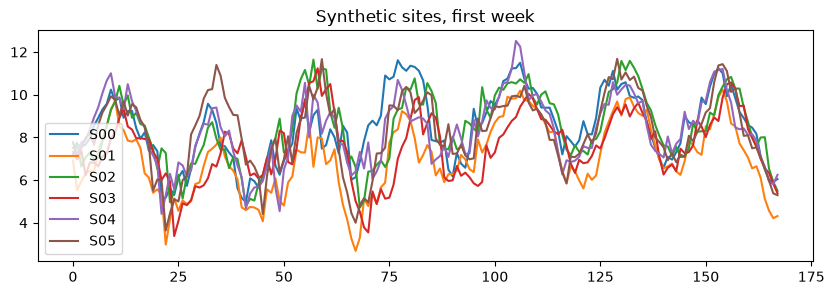

In [3]:
import pandas as pd
df = load_sites_csv(find_csv('synthetic_sites.csv')); W, static, names = to_tensor(df)
pd.DataFrame(W[:24*7], columns=names).plot(figsize=(10,3), title='Synthetic sites, first week'); plt.show()

## 2. Windows over all sites → target site at horizons 1 h and 6 h

In [4]:
hz=[1,6]; T=len(W); a1,a2=int(T*.7),int(T*.85); mu,sd=W[:a1].mean(),W[:a1].std(); Wn=(W-mu)/sd; st=(static-static.mean(0))/(static.std(0)+1e-6)
def part(lo,hi):
    X,Y,i=windows(Wn[lo:hi],24,hz)
    last=X[:,-1,:1]   # last reading of the target site (persistence)
    return torch.tensor(X),torch.tensor(st[i]),torch.tensor(Y-last),last   # target = change from last reading
TR,VA,TE=part(0,a1),part(a1-24,a2),part(a2-24,T); tr,va,te=TR[:3],VA[:3],TE[:3]

## 3. Layer 1 GA (architecture genes) and Layer 2 PSO (learning rate, dropout) — tiny budgets

In [5]:
sub = tuple(t[::4] for t in tr)   # search on every 4th window to keep the demo fast
best,_ = ga(lambda c: train(c,(sub,va),1)[1], pop=3, gens=1)
gb,_ = pso(lambda p: train({**best,'lr':10**p[0],'dropout':p[1]},(sub,va),1)[1], [(-3.5,-2.0),(0.0,0.3)], particles=2, iters=1)
cfg = {**best,'lr':float(10**gb[0]),'dropout':float(gb[1])}; cfg

GA gen 0: best val loss 0.3171 {'filters': 64, 'hidden': 32, 'n_rules': 8}


PSO iter 0: best val loss 0.2332 at [-2.3445, 0.00527]


{'filters': 16,
 'hidden': 16,
 'n_rules': 16,
 'lr': 0.004523745601612876,
 'dropout': 0.005270388171536292}

## 4. Train the ANFIS → CNN-LSTM quantile model, MC-dropout predict, evaluate

In [6]:
m,_ = train(cfg,(tr,va),EPOCHS)
last = TE[3]                                   # persistence, normalized
q = (mc_predict(m, te[0], te[1], n=10) + last[:,:,None])*sd+mu   # add the change back
y = (te[2].numpy() + last)*sd+mu; pers = last*sd+mu
for j,h in enumerate(hz):
    print(f'{h}h model      ', {k: round(v,3) for k,v in regression_metrics(y[:,j], q[:,j,2]).items()}, 'CRPS=%.3f' % crps_from_quantiles(q[:,j], y[:,j]))
    print(f'{h}h persistence', {k: round(v,3) for k,v in regression_metrics(y[:,j], pers[:,0]).items()})

1h model       {'MAE': 0.495, 'RMSE': 0.666, 'MAPE_%': 5.448, 'R2': 0.838} CRPS=0.326
1h persistence {'MAE': 0.538, 'RMSE': 0.729, 'MAPE_%': 5.982, 'R2': 0.806}
6h model       {'MAE': 1.261, 'RMSE': 1.557, 'MAPE_%': 13.273, 'R2': 0.11} CRPS=0.801
6h persistence {'MAE': 1.753, 'RMSE': 2.17, 'MAPE_%': 19.577, 'R2': -0.728}


### Result in plain words
- **1h ahead:** model RMSE 0.666 m/s vs persistence 0.729 m/s (R² 0.838 vs 0.806). The model beats persistence here.
- **6h ahead:** model RMSE 1.557 m/s vs persistence 2.170 m/s (R² 0.110 vs -0.728). The model beats persistence here.

These numbers come from about a minute of training on synthetic data. They show that the code works and learns something useful beyond "next hour = this hour"; they are not the paper's results.

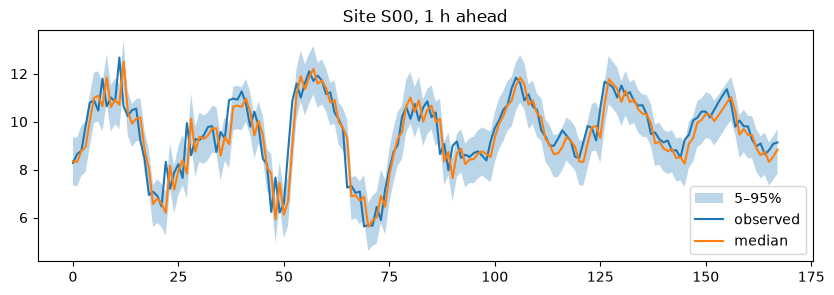

In [7]:
s=slice(0,168*len(names),len(names)); plt.figure(figsize=(10,3)); plt.fill_between(range(168), q[s,0,0], q[s,0,-1], alpha=.3, label='5–95%'); plt.plot(y[s,0], label='observed'); plt.plot(q[s,0,2], label='median'); plt.legend(); plt.title('Site S00, 1 h ahead'); plt.show()